# 🇱🇰 LankaEnsemble Lab — Ensemble Learning Dashboard on Sri Lankan Data
### Bagging · Boosting · Stacking · RF vs XGBoost · Hybrid RF + ANN · Hybrid RF + ARIMA

**Student:** B.N.V. Gunathilaka &nbsp;|&nbsp; **Index:** 224059P &nbsp;|&nbsp; **Faculty of IT, University of Moratuwa**
**Assignment:** Hands-on Project — Ensemble Learning Dashboard (10%)

---
## The story
Sri Lanka's mobile market is crowded and **most users carry two SIMs**. When a competitor sends a cheaper data offer, a customer can switch overnight — no contract, no paperwork. At the same time, ordinary Sri Lankans make two other high-stakes decisions using guesswork: **"Is this ikman.lk car price fair?"** and **"What will the weather be like tomorrow in Colombo?"**

This project builds one **ensemble-learning lab** that answers all three with Sri Lankan data:

| Part | Problem | Sri Lankan dataset | Ensemble idea |
|---|---|---|---|
| A | Who will churn? (classification) | Mobile operator customers in 25 districts | **Bagging vs Boosting vs Stacking** (10 models) |
| B | Is XGBoost really better than Random Forest? | Same | **RF vs XGBoost** with repeated CV + statistical test |
| C | What is a fair used-car price? (regression) | ikman.lk-style listings (LKR) | **Hybrid RF + ANN** (blend, residual, stacking) |
| D | Tomorrow's Colombo temperature (time series) | Colombo daily weather (Open-Meteo, real) | **Hybrid ARIMA + RF** (Zhang-style residual hybrid) |
| E | 💡 Innovation | — | **Retention Budget Optimizer** (LKR) + **ikman Deal Checker** with RF uncertainty |

### ⚠️ Data honesty statement
* **Colombo weather** is **real** data downloaded from the free Open-Meteo historical archive (ERA5 reanalysis) for Colombo (6.93°N, 79.85°E). If there is no internet, a synthetic fallback with the same columns is used — the notebook prints which one was used.
* **Telecom churn** and **vehicle prices** are **synthetic, Sri Lankan-context datasets** that I generated (code in Section 1), because real operator customer records are confidential and scraping ikman.lk at scale breaches its terms of use. The generators encode real local patterns: district populations, Tamil/Sinhala language areas, rural network quality, dual-SIM behaviour, eZ Cash/reload payments, common Sri Lankan car models, recondition vs registered, the 2020–2024 import-ban price premium, etc. The same code works unchanged on a real CSV with the same columns.

### 🤖 Generative AI declaration (required by the module)
Parts of the code in this notebook and the Streamlit dashboard UI were **generated with the help of Claude (Anthropic)**, then reviewed, run and checked by me. The analysis choices, interpretation and conclusions are my own responsibility.

## 0. Setup
Runs on **Google Colab** (Runtime → Run all) or any Jupyter. The copy in the GitHub repository was executed end-to-end automatically by **GitHub Actions** (`.github/workflows/run-notebook.yml`), so every output below is real.

In [1]:
%pip install -q xgboost lightgbm catboost statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings, time, json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_predict, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier,
                              VotingClassifier, RandomForestRegressor, StackingRegressor)
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, roc_curve, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error)
import xgboost as xgb
import lightgbm as lgb
from statsmodels.tsa.arima.model import ARIMA
try:
    from catboost import CatBoostClassifier
    HAS_CATBOOST = True
except Exception:
    HAS_CATBOOST = False

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
DATA = Path("data"); DATA.mkdir(exist_ok=True)
print("xgboost", xgb.__version__, "| lightgbm", lgb.__version__, "| catboost available:", HAS_CATBOOST)

xgboost 3.2.0 | lightgbm 4.7.0 | catboost available: True


## 1. Data
### 1.1 Sri Lankan-context dataset generators (telecom churn, ikman-style vehicles, weather fallback)
Fixed seed → every run produces the identical datasets.

In [3]:
"""
generate_datasets.py
--------------------
Creates the three Sri Lankan-context datasets used in this project.

IMPORTANT (stated honestly in the report/video):
  * sl_telecom_churn.csv  -> SYNTHETIC. Simulated customers of a Sri Lankan mobile
    operator (25 districts, LKR spend, eZ Cash/reload payments, dual-SIM behaviour).
  * sl_vehicle_prices.csv -> SYNTHETIC. Simulated ikman.lk-style used-vehicle listings
    (common Sri Lankan models, LKR prices, recondition vs registered, import-ban effect).
  * colombo_weather_daily.csv -> SYNTHETIC FALLBACK only. The notebook and dashboard first
    try to download REAL Colombo daily weather from the free Open-Meteo archive API and
    use this file only if there is no internet.

The generating rules are based on public, well-known patterns of the Sri Lankan context
(population by district, monsoon rainfall seasons, vehicle depreciation, 2020-2024 vehicle
import restrictions). Fixed random seed -> fully reproducible.

Run:  python generate_datasets.py
"""
import numpy as np
import pandas as pd
from pathlib import Path

rng = np.random.default_rng(2026)

# --------------------------------------------------------------------------------------
# 1. TELECOM CHURN
# --------------------------------------------------------------------------------------
# district: (population '000, province, urban share, network quality baseline 1-5, tamil share)
DISTRICTS = {
    "Colombo": (2470, "Western", 0.85, 4.5, 0.12), "Gampaha": (2430, "Western", 0.55, 4.3, 0.05),
    "Kalutara": (1300, "Western", 0.30, 4.0, 0.06), "Kandy": (1460, "Central", 0.35, 3.9, 0.15),
    "Matale": (520, "Central", 0.15, 3.4, 0.10), "Nuwara Eliya": (760, "Central", 0.12, 3.0, 0.55),
    "Galle": (1100, "Southern", 0.30, 4.0, 0.03), "Matara": (840, "Southern", 0.25, 3.8, 0.03),
    "Hambantota": (650, "Southern", 0.12, 3.4, 0.02), "Jaffna": (620, "Northern", 0.30, 3.3, 0.98),
    "Kilinochchi": (130, "Northern", 0.10, 2.6, 0.97), "Mannar": (110, "Northern", 0.10, 2.6, 0.90),
    "Vavuniya": (190, "Northern", 0.20, 2.9, 0.85), "Mullaitivu": (100, "Northern", 0.05, 2.4, 0.95),
    "Batticaloa": (590, "Eastern", 0.25, 3.1, 0.90), "Ampara": (720, "Eastern", 0.20, 3.0, 0.60),
    "Trincomalee": (420, "Eastern", 0.25, 3.1, 0.70), "Kurunegala": (1700, "North Western", 0.20, 3.7, 0.05),
    "Puttalam": (820, "North Western", 0.18, 3.4, 0.25), "Anuradhapura": (930, "North Central", 0.15, 3.3, 0.05),
    "Polonnaruwa": (440, "North Central", 0.12, 3.1, 0.05), "Badulla": (870, "Uva", 0.12, 3.0, 0.25),
    "Monaragala": (500, "Uva", 0.08, 2.8, 0.05), "Ratnapura": (1150, "Sabaragamuwa", 0.15, 3.3, 0.10),
    "Kegalle": (870, "Sabaragamuwa", 0.15, 3.5, 0.08),
}


def make_churn(n=8000):
    names = list(DISTRICTS)
    w = np.array([DISTRICTS[d][0] for d in names], float)
    district = rng.choice(names, n, p=w / w.sum())
    prov = np.array([DISTRICTS[d][1] for d in district])
    urban_p = np.array([DISTRICTS[d][2] for d in district])
    netq_base = np.array([DISTRICTS[d][3] for d in district])
    tamil_p = np.array([DISTRICTS[d][4] for d in district])

    area = np.where(rng.random(n) < urban_p, "Urban", "Rural")
    lang_r = rng.random(n)
    language = np.where(lang_r < tamil_p, "Tamil", np.where(lang_r < tamil_p + 0.08, "English", "Sinhala"))
    age = np.clip(rng.normal(36, 12, n), 16, 78).round().astype(int)
    gender = rng.choice(["Male", "Female"], n, p=[0.52, 0.48])
    plan = np.where(rng.random(n) < 0.22 + 0.15 * (area == "Urban"), "Postpaid", "Prepaid")
    tenure = np.clip(rng.gamma(1.6, 18, n), 1, 144).round().astype(int)

    is_post = plan == "Postpaid"
    spend = np.where(is_post, rng.lognormal(np.log(2600), 0.45, n), rng.lognormal(np.log(850), 0.6, n))
    spend = np.round(spend / 10) * 10
    data_gb = np.clip(rng.gamma(2.0, 4.0, n) * (1.6 - (age - 16) / 80) * np.where(area == "Urban", 1.35, 0.9), 0, 120).round(1)
    voice_min = np.clip(rng.gamma(2.2, 90, n) * (0.6 + (age - 16) / 60), 0, 2500).round().astype(int)
    netq = np.clip(netq_base - np.where(area == "Rural", 0.4, 0) + rng.normal(0, 0.45, n), 1, 5).round(1)
    drop_rate = np.clip(rng.gamma(1.5, 0.6, n) * (5.6 - netq) / 2, 0, 15).round(2)
    complaints = rng.poisson(np.clip(0.25 + 0.35 * (4.2 - netq) + 0.15 * drop_rate, 0.05, None))
    dual_sim = (rng.random(n) < 0.30 + 0.20 * (age < 30)).astype(int)
    fibre = (rng.random(n) < np.where(area == "Urban", 0.22, 0.06)).astype(int)
    comp_offer = (rng.random(n) < 0.35).astype(int)
    days_reload = np.where(is_post, 0, np.clip(rng.exponential(9, n), 0, 60).round()).astype(int)
    late_bill = np.where(is_post, rng.poisson(0.6, n), 0)
    contract_left = np.where(is_post, rng.integers(0, 25, n), 0)
    pay = np.where(is_post, rng.choice(["Bank card", "Bill payment", "eZ Cash"], n, p=[0.45, 0.35, 0.20]),
                   rng.choice(["Reload card", "Retailer reload", "eZ Cash", "Bank card"], n, p=[0.25, 0.45, 0.22, 0.08]))
    pts = (rng.random(n) < 0.3 + 0.004 * tenure).astype(int)

    z = (-2.35
         + 1.00 * dual_sim
         + 0.90 * comp_offer * dual_sim            # interaction: competitor offer hits dual-SIM users
         + 0.25 * comp_offer
         + 0.38 * complaints
         + 0.85 * (netq < 2.6)
         + 0.75 * ((data_gb > 15) & (netq < 3.2))  # heavy data users on poor network
         + 0.055 * np.minimum(days_reload, 40)      # inactivity (prepaid)
         + 0.30 * late_bill
         - 0.55 * np.log1p(tenure) + 1.5
         - 1.20 * fibre
         - 0.90 * (is_post & (contract_left > 6))
         - 0.45 * pts
         + 0.45 * (age < 25)
         + 0.25 * (spend < 400)
         + rng.normal(0, 0.55, n))
    churn = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)

    return pd.DataFrame({
        "customer_id": [f"SLC{100000 + i}" for i in range(n)],
        "district": district, "province": prov, "area_type": area, "language": language,
        "age": age, "gender": gender, "plan_type": plan, "tenure_months": tenure,
        "monthly_spend_lkr": spend, "data_usage_gb": data_gb, "voice_minutes": voice_min,
        "network_quality_score": netq, "dropped_call_rate_pct": drop_rate,
        "complaints_6m": complaints, "dual_sim": dual_sim, "has_fibre_bundle": fibre,
        "competitor_offer_received": comp_offer, "days_since_last_reload": days_reload,
        "late_bill_payments": late_bill, "contract_months_left": contract_left,
        "payment_method": pay, "uses_loyalty_points": pts, "churn": churn,
    })


# --------------------------------------------------------------------------------------
# 2. VEHICLE PRICES (ikman.lk style)
# --------------------------------------------------------------------------------------
# model: (brand, fuel, engine_cc, body, base price LKR mn for a 2018-ish unit, first yom, annual depreciation)
MODELS = {
    "Aqua": ("Toyota", "Hybrid", 1500, "Hatchback", 9.6, 2012, 0.055),
    "Vitz": ("Toyota", "Petrol", 1000, "Hatchback", 8.2, 2005, 0.050),
    "Prius": ("Toyota", "Hybrid", 1800, "Sedan", 13.8, 2010, 0.065),
    "Axio": ("Toyota", "Hybrid", 1500, "Sedan", 11.8, 2008, 0.050),
    "Premio": ("Toyota", "Petrol", 1500, "Sedan", 17.5, 2008, 0.045),
    "C-HR": ("Toyota", "Hybrid", 1800, "SUV", 16.8, 2017, 0.060),
    "Land Cruiser Prado": ("Toyota", "Diesel", 2800, "SUV", 48.0, 2005, 0.045),
    "Wagon R": ("Suzuki", "Hybrid", 660, "Hatchback", 6.9, 2014, 0.055),
    "Alto": ("Suzuki", "Petrol", 800, "Hatchback", 3.6, 2005, 0.050),
    "Swift": ("Suzuki", "Petrol", 1200, "Hatchback", 6.6, 2008, 0.055),
    "Fit": ("Honda", "Hybrid", 1500, "Hatchback", 8.6, 2011, 0.060),
    "Vezel": ("Honda", "Hybrid", 1500, "SUV", 14.2, 2014, 0.055),
    "Grace": ("Honda", "Hybrid", 1500, "Sedan", 10.2, 2014, 0.060),
    "Civic": ("Honda", "Petrol", 1500, "Sedan", 15.5, 2006, 0.055),
    "Leaf": ("Nissan", "Electric", 0, "Hatchback", 7.8, 2012, 0.110),
    "X-Trail": ("Nissan", "Hybrid", 2000, "SUV", 16.2, 2010, 0.065),
    "Montero": ("Mitsubishi", "Diesel", 3200, "SUV", 29.0, 2005, 0.050),
    "Axia": ("Perodua", "Petrol", 1000, "Hatchback", 4.9, 2015, 0.060),
    "Panda": ("Micro", "Petrol", 1000, "Hatchback", 2.7, 2010, 0.070),
    "Axela": ("Mazda", "Petrol", 1500, "Sedan", 9.2, 2010, 0.065),
    "Tucson": ("Hyundai", "Diesel", 2000, "SUV", 15.2, 2010, 0.065),
    "Sorento": ("Kia", "Diesel", 2200, "SUV", 17.4, 2010, 0.065),
}
MODEL_POP = {"Aqua": 12, "Vitz": 10, "Prius": 6, "Axio": 7, "Premio": 6, "C-HR": 3, "Land Cruiser Prado": 2,
             "Wagon R": 11, "Alto": 9, "Swift": 4, "Fit": 7, "Vezel": 6, "Grace": 4, "Civic": 2, "Leaf": 3,
             "X-Trail": 2, "Montero": 2, "Axia": 3, "Panda": 2, "Axela": 2, "Tucson": 1.5, "Sorento": 1.5}
CITY = {"Colombo": 0.34, "Gampaha": 0.20, "Kandy": 0.09, "Kurunegala": 0.08, "Kalutara": 0.06, "Galle": 0.06,
        "Matara": 0.04, "Ratnapura": 0.03, "Anuradhapura": 0.03, "Jaffna": 0.03, "Badulla": 0.02, "Kegalle": 0.02}


def make_vehicles(n=6000, ref_year=2025):
    names = list(MODEL_POP)
    p = np.array([MODEL_POP[m] for m in names]); p = p / p.sum()
    model = rng.choice(names, n, p=p)
    rows = []
    for m in model:
        brand, fuel, cc, body, base, first, dep = MODELS[m]
        yom = int(np.clip(rng.normal(2015, 3.6), first, 2024))
        age = ref_year - yom
        recon = yom >= 2022 and rng.random() < 0.55          # post-2025 import reopening: unregistered recon units
        condition = "Recondition" if recon else "Used"
        mileage = int(max(500, rng.normal(11500 * age + (2000 if not recon else 0), 5500 + 1500 * age)))
        if recon:
            mileage = int(rng.uniform(5000, 40000))
        trans = "Manual" if (m in ("Alto", "Panda", "Montero") and rng.random() < 0.45) else "Automatic"
        owners = 0 if recon else int(np.clip(rng.poisson(0.6 + age / 7) + 1, 1, 5))
        district = rng.choice(list(CITY), p=list(CITY.values()))
        seller = rng.choice(["Dealer", "Owner"], p=[0.45, 0.55])
        on_lease = int(rng.random() < 0.18 and age < 9)
        rows.append([brand, m, fuel, cc, body, yom, age, mileage, trans, condition, owners, district, seller,
                     on_lease, base, dep])
    df = pd.DataFrame(rows, columns=["brand", "model", "fuel_type", "engine_cc", "body_type", "year_of_manufacture",
                                     "vehicle_age", "mileage_km", "transmission", "condition", "previous_owners",
                                     "district", "seller_type", "on_lease", "_base", "_dep"])
    age = df.vehicle_age.values
    km = df.mileage_km.values
    price = (df._base.values * np.exp(-df._dep.values * (age - 7))
             * np.exp(-0.0000028 * np.maximum(km - 12000 * age, -40000))   # above-average mileage penalty
             * np.where(df.condition == "Recondition", 1.18, 1.0)
             * np.where((df.year_of_manufacture >= 2015) & (df.year_of_manufacture <= 2019), 1.08, 1.0)  # import-ban scarcity
             * np.where(df.transmission == "Manual", 0.93, 1.0)
             * (1 - 0.025 * np.maximum(df.previous_owners.values - 1, 0))
             * np.where(df.district == "Colombo", 1.03, 1.0)
             * np.where(df.seller_type == "Dealer", 1.04, 1.0)
             * np.where(df.on_lease == 1, 0.97, 1.0)
             * np.where((df.fuel_type == "Hybrid") & (age > 10), 0.90, 1.0)   # old hybrid battery risk
             * rng.lognormal(0, 0.07, len(df)))
    df["price_lkr_mn"] = np.round(price, 2)
    return df.drop(columns=["_base", "_dep"])


# --------------------------------------------------------------------------------------
# 3. COLOMBO DAILY WEATHER (synthetic fallback; same column names as Open-Meteo)
# --------------------------------------------------------------------------------------
def make_weather(start="2015-01-01", end="2025-12-31"):
    dates = pd.date_range(start, end, freq="D")
    n = len(dates)
    month_rain = {1: 60, 2: 70, 3: 130, 4: 250, 5: 390, 6: 190, 7: 135, 8: 110, 9: 225, 10: 350, 11: 320, 12: 150}
    m = dates.month.values
    mean_rain = np.array([month_rain[k] for k in m]) / dates.days_in_month.values
    p_wet = np.clip(0.18 + mean_rain / 18, 0.15, 0.85)
    wet = rng.random(n) < p_wet
    rain = np.where(wet, rng.gamma(0.9, mean_rain / p_wet / 0.9), 0.0)
    doy = dates.dayofyear.values
    seasonal = 27.4 + 0.75 * np.sin(2 * np.pi * (doy - 30) / 365.25) + 0.35 * np.sin(4 * np.pi * (doy - 60) / 365.25)
    trend = 0.025 * (dates.year.values - 2015)
    enso = 0.35 * np.sin(2 * np.pi * np.arange(n) / (365.25 * 3.7))       # slow multi-year cycle (ENSO-like)
    anom = np.zeros(n)
    eps = rng.normal(0, 0.38, n)
    for t in range(1, n):
        anom[t] = 0.72 * anom[t - 1] - 0.10 * (anom[t - 2] if t > 1 else 0) + eps[t]
    temp = seasonal + trend + enso + anom - 0.018 * np.minimum(rain, 80)
    sw = np.isin(m, [5, 6, 7, 8, 9])
    wind = np.clip(rng.normal(np.where(sw, 24, 15), 4, n) + 0.08 * np.minimum(rain, 60), 5, None)
    rad = np.clip(rng.normal(21, 2.5, n) - 0.10 * np.minimum(rain, 70), 6, 28)
    return pd.DataFrame({
        "date": dates.strftime("%Y-%m-%d"),
        "temperature_2m_mean": temp.round(1),
        "temperature_2m_max": (temp + rng.normal(3.6, 0.6, n) - 0.01 * np.minimum(rain, 80)).round(1),
        "temperature_2m_min": (temp - rng.normal(2.9, 0.5, n)).round(1),
        "precipitation_sum": rain.round(1),
        "wind_speed_10m_max": wind.round(1),
        "shortwave_radiation_sum": rad.round(2),
    })

In [4]:
churn_df = make_churn()
veh_df = make_vehicles()
churn_df.to_csv(DATA / "sl_telecom_churn.csv", index=False)
veh_df.to_csv(DATA / "sl_vehicle_prices.csv", index=False)
print("Telecom churn:", churn_df.shape, "| churn rate = %.1f%%" % (100 * churn_df.churn.mean()))
print("Vehicles     :", veh_df.shape)
churn_df.head()

Telecom churn: (8000, 24) | churn rate = 24.0%
Vehicles     : (6000, 15)


,customer_id,district,province,area_type,language,age,gender,plan_type,tenure_months,monthly_spend_lkr,...,complaints_6m,dual_sim,has_fibre_bundle,competitor_offer_received,days_since_last_reload,late_bill_payments,contract_months_left,payment_method,uses_loyalty_points,churn
0,SLC100000,Gampaha,Western,Urban,Sinhala,39,Male,Prepaid,2,650.0,...,0,0,0,1,13,0,0,eZ Cash,1,1
1,SLC100001,Ampara,Eastern,Urban,Tamil,42,Female,Postpaid,27,1170.0,...,1,0,0,0,0,1,6,eZ Cash,0,1
2,SLC100002,Matara,Southern,Urban,Sinhala,47,Male,Postpaid,9,3410.0,...,1,1,0,0,0,0,16,Bill payment,1,0
3,SLC100003,Matale,Central,Rural,Tamil,45,Male,Postpaid,17,1920.0,...,1,1,0,0,0,0,15,Bill payment,0,0
4,SLC100004,Matale,Central,Rural,Sinhala,28,Male,Prepaid,43,1510.0,...,3,1,0,1,3,0,0,Reload card,0,0


### 1.2 Real Colombo daily weather (Open-Meteo archive API)

In [5]:
def load_colombo_weather(start="2015-01-01", end="2026-10-31"):
    url = ("https://archive-api.open-meteo.com/v1/archive?latitude=6.9271&longitude=79.8612"
           f"&start_date={start}&end_date={end}"
           "&daily=temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,"
           "wind_speed_10m_max,shortwave_radiation_sum&timezone=Asia%2FColombo")
    try:
        import requests
        r = requests.get(url, timeout=60); r.raise_for_status()
        d = pd.DataFrame(r.json()["daily"]).rename(columns={"time": "date"})
        source = "REAL – Open-Meteo archive (ERA5), Colombo"
    except Exception as e:
        print("Download failed -> using synthetic fallback:", e)
        d = make_weather(start, end)
        source = "SYNTHETIC fallback"
    d["date"] = pd.to_datetime(d["date"])
    d = d.set_index("date").asfreq("D").interpolate(limit_direction="both")
    return d, source

wx, WX_SOURCE = load_colombo_weather()
wx.to_csv(DATA / "colombo_weather_daily_used.csv")
print("Weather source:", WX_SOURCE, "|", wx.shape, wx.index.min().date(), "→", wx.index.max().date())
wx.tail()

Weather source: REAL – Open-Meteo archive (ERA5), Colombo | (4322, 6) 2015-01-01 → 2026-10-31


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max,shortwave_radiation_sum
date,,,,,,
2026-10-27,26.8,30.6,24.0,2.9,13.3,16.33
2026-10-28,27.7,30.1,25.8,8.0,17.6,16.94
2026-10-29,27.3,29.7,25.9,5.3,15.3,16.97
2026-10-30,27.8,30.4,25.7,0.8,11.6,20.47
2026-10-31,27.5,31.3,24.1,1.2,11.3,22.00


### 1.3 Quick EDA — what drives churn?

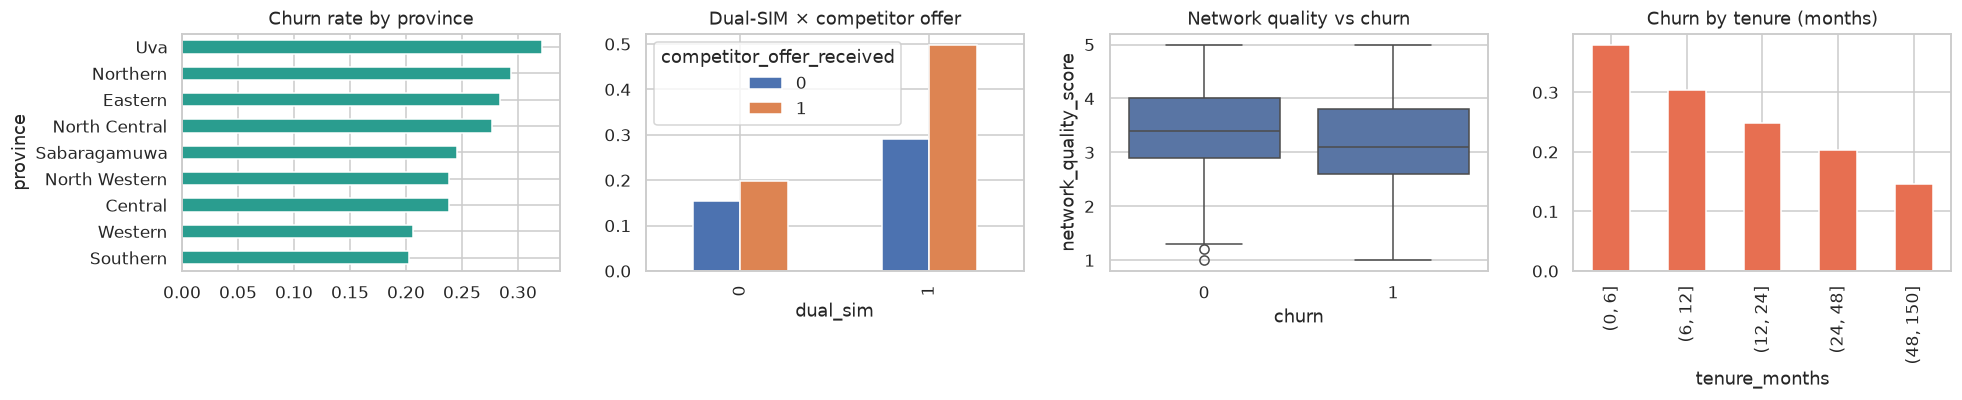

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
churn_df.groupby("province").churn.mean().sort_values().plot.barh(ax=ax[0], color="#2a9d8f"); ax[0].set_title("Churn rate by province")
churn_df.groupby(["dual_sim", "competitor_offer_received"]).churn.mean().unstack().plot.bar(ax=ax[1]); ax[1].set_title("Dual-SIM × competitor offer")
sns.boxplot(data=churn_df, x="churn", y="network_quality_score", ax=ax[2]); ax[2].set_title("Network quality vs churn")
churn_df.groupby(pd.cut(churn_df.tenure_months, [0, 6, 12, 24, 48, 150])).churn.mean().plot.bar(ax=ax[3], color="#e76f51"); ax[3].set_title("Churn by tenure (months)")
plt.tight_layout(); plt.show()

**Observation:** churn is driven by *interactions* (dual-SIM users who receive a competitor offer churn far more than either factor alone), by poor rural network quality (North/East districts), and by short tenure. Interactions and thresholds like these are exactly what tree ensembles are good at.

---
## 2. Part A — Ensemble Arena: Bagging vs Boosting vs Stacking (telecom churn)

In [7]:
TARGET = "churn"
cat_cols = ["district", "province", "area_type", "language", "gender", "plan_type", "payment_method"]
num_cols = [c for c in churn_df.columns if c not in cat_cols + ["customer_id", TARGET]]

Xc = churn_df[cat_cols + num_cols]; yc = churn_df[TARGET].values
Xc_tr_raw, Xc_te_raw, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, stratify=yc, random_state=SEED)

pre_c = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
                           ("num", StandardScaler(), num_cols)])
Xc_tr = pre_c.fit_transform(Xc_tr_raw); Xc_te = pre_c.transform(Xc_te_raw)
feat_c = [f.split("__", 1)[1] for f in pre_c.get_feature_names_out()]
print("Train", Xc_tr.shape, "Test", Xc_te.shape, "| features:", len(feat_c))

Train (6400, 63) Test (1600, 63) | features: 63


In [8]:
def churn_models():
    m = {
        # --- baselines
        "Logistic Regression (baseline)": ("Baseline", LogisticRegression(max_iter=2000)),
        "Single Decision Tree": ("Baseline", DecisionTreeClassifier(max_depth=6, random_state=SEED)),
        # --- BAGGING family (parallel, reduce variance)
        "Bagging (Decision Trees)": ("Bagging", BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=SEED, n_jobs=-1)),
        "Random Forest": ("Bagging", RandomForestClassifier(n_estimators=400, min_samples_leaf=3, random_state=SEED, n_jobs=-1)),
        "Extra Trees": ("Bagging", ExtraTreesClassifier(n_estimators=400, min_samples_leaf=3, random_state=SEED, n_jobs=-1)),
        # --- BOOSTING family (sequential, reduce bias)
        "AdaBoost": ("Boosting", AdaBoostClassifier(n_estimators=300, learning_rate=0.5, random_state=SEED)),
        "Gradient Boosting (sklearn)": ("Boosting", GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=SEED)),
        "XGBoost": ("Boosting", xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                                                  colsample_bytree=0.8, eval_metric="logloss", random_state=SEED, n_jobs=-1)),
        "LightGBM": ("Boosting", lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=15, subsample=0.8,
                                                    subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)),
    }
    if HAS_CATBOOST:
        m["CatBoost"] = ("Boosting", CatBoostClassifier(iterations=400, learning_rate=0.05, depth=5, random_seed=SEED, verbose=0))
    # --- STACKING / VOTING (heterogeneous learners + meta-learner)
    base = [("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1)),
            ("xgb", xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                                      eval_metric="logloss", random_state=SEED, n_jobs=-1)),
            ("lgbm", lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1)),
            ("lr", LogisticRegression(max_iter=2000))]
    m["Stacking (RF+XGB+LGBM+LR → LR)"] = ("Stacking", StackingClassifier(base, final_estimator=LogisticRegression(max_iter=2000),
                                                                          cv=5, stack_method="predict_proba", n_jobs=-1))
    m["Soft Voting (RF+XGB+LGBM+LR)"] = ("Stacking", VotingClassifier(base, voting="soft", n_jobs=-1))
    return m

def clf_metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {"Accuracy": accuracy_score(y, yhat), "Precision": precision_score(y, yhat), "Recall": recall_score(y, yhat),
            "F1": f1_score(y, yhat), "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p)}

rows, probs, fitted = [], {}, {}
for name, (family, model) in churn_models().items():
    t0 = time.time(); model.fit(Xc_tr, yc_tr); secs = time.time() - t0
    p = model.predict_proba(Xc_te)[:, 1]
    probs[name], fitted[name] = p, model
    rows.append({"Model": name, "Family": family, **clf_metrics(yc_te, p), "Train time (s)": secs})
    print(f"{name:38s} AUC={rows[-1]['ROC-AUC']:.4f}  F1={rows[-1]['F1']:.3f}  ({secs:.1f}s)")

arena = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
arena.style.format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]} | {"Train time (s)": "{:.1f}"}) \
     .background_gradient(subset=["ROC-AUC", "F1"], cmap="Greens")

Logistic Regression (baseline)         AUC=0.7741  F1=0.444  (0.0s)
Single Decision Tree                   AUC=0.7077  F1=0.403  (0.0s)


Bagging (Decision Trees)               AUC=0.7433  F1=0.424  (5.0s)


Random Forest                          AUC=0.7793  F1=0.289  (1.1s)


Extra Trees                            AUC=0.7549  F1=0.282  (1.0s)


AdaBoost                               AUC=0.7850  F1=0.388  (2.0s)


Gradient Boosting (sklearn)            AUC=0.7804  F1=0.427  (3.9s)


... (2 outputs left out)

CatBoost                               AUC=0.7852  F1=0.432  (0.8s)


Stacking (RF+XGB+LGBM+LR → LR)         AUC=0.7848  F1=0.451  (7.2s)


Soft Voting (RF+XGB+LGBM+LR)           AUC=0.7842  F1=0.434  (1.3s)


,Model,Family,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Train time (s)
0,CatBoost,Boosting,0.7981,0.6649,0.3203,0.4323,0.7852,0.5512,0.8
1,AdaBoost,Boosting,0.8006,0.7372,0.2630,0.3877,0.7850,0.5688,2.0
2,Stacking (RF+XGB+LGBM+LR → LR),Stacking,0.7994,0.6567,0.3438,0.4513,0.7848,0.5690,7.2
3,Soft Voting (RF+XGB+LGBM+LR),Stacking,0.8044,0.7101,0.3125,0.4340,0.7842,0.5675,1.3
4,Gradient Boosting (sklearn),Boosting,0.7969,0.6612,0.3151,0.4268,0.7804,0.5584,3.9
5,Random Forest,Bagging,0.7881,0.7419,0.1797,0.2893,0.7793,0.5618,1.1
6,XGBoost,Boosting,0.7969,0.6453,0.3411,0.4463,0.7743,0.5523,0.3
7,Logistic Regression (baseline),Baseline,0.7981,0.6548,0.3359,0.4441,0.7741,0.5564,0.0
8,LightGBM,Boosting,0.7931,0.6318,0.3307,0.4342,0.7700,0.5405,0.2
9,Extra Trees,Bagging,0.7869,0.7363,0.1745,0.2821,0.7549,0.5319,1.0


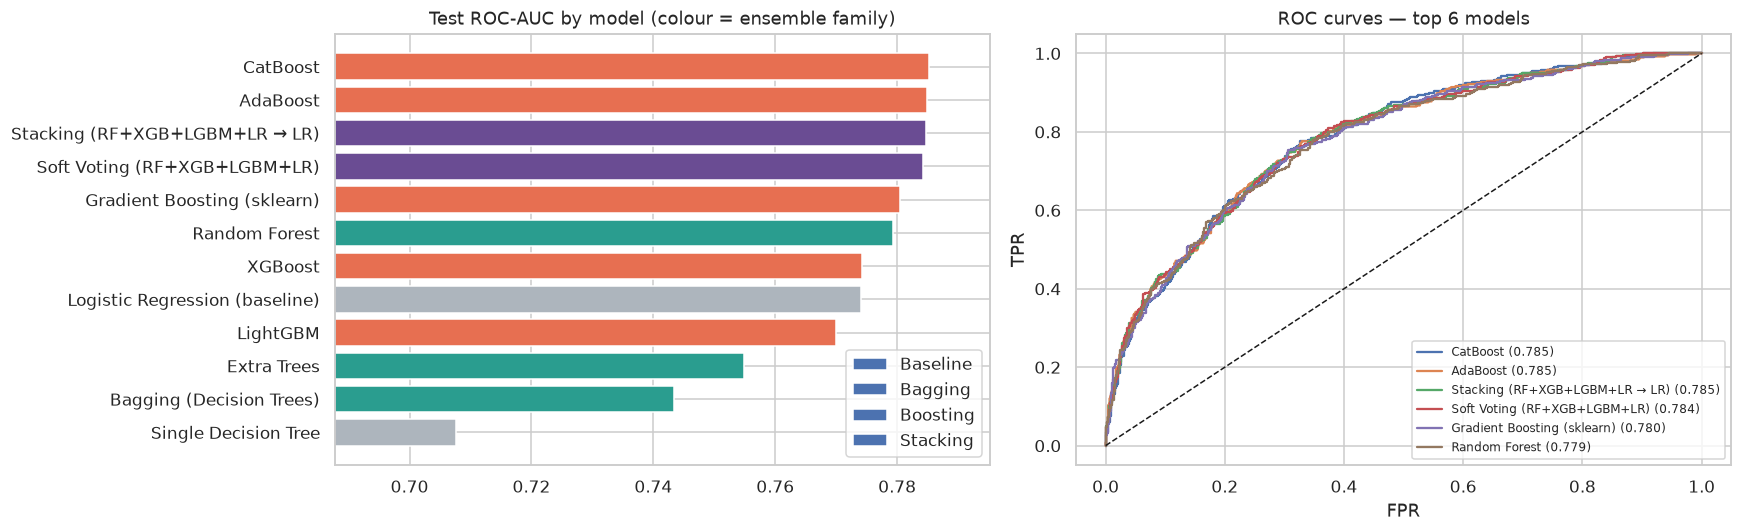

          ROC-AUC      F1  Train time (s)
Family                                   
Stacking   0.7845  0.4426          4.2624
Boosting   0.7790  0.4255          1.4406
Bagging    0.7592  0.3319          2.3776
Baseline   0.7409  0.4234          0.0282


In [9]:
fam_colors = {"Baseline": "#adb5bd", "Bagging": "#2a9d8f", "Boosting": "#e76f51", "Stacking": "#6a4c93"}
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
a = arena.sort_values("ROC-AUC")
ax[0].barh(a.Model, a["ROC-AUC"], color=[fam_colors[f] for f in a.Family])
ax[0].set_xlim(a["ROC-AUC"].min() - 0.02, a["ROC-AUC"].max() + 0.01); ax[0].set_title("Test ROC-AUC by model (colour = ensemble family)")
for f, c in fam_colors.items(): ax[0].barh([], [], color=c, label=f)
ax[0].legend(loc="lower right")
for name in arena.Model[:6]:
    fpr, tpr, _ = roc_curve(yc_te, probs[name]); ax[1].plot(fpr, tpr, label=f"{name} ({roc_auc_score(yc_te, probs[name]):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("ROC curves — top 6 models"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(arena.groupby("Family")[["ROC-AUC", "F1", "Train time (s)"]].mean().sort_values("ROC-AUC", ascending=False).round(4))

### Interpreting Part A — why do the families behave differently?
* **Single tree → Bagging/RF:** a single deep tree has *high variance* (it memorises noise). Bagging trains many trees on bootstrap samples and averages them, which cancels much of that variance — hence the large jump from the single tree to Bagging/RF/Extra Trees. RF adds *random feature subsets* at each split, de-correlating the trees further, so it normally beats plain bagging.
* **Boosting:** boosting builds shallow trees *sequentially*, each one fixing the errors of the previous ones, so it mainly reduces *bias*. Our churn signal is made of many small additive effects plus a few interactions (dual-SIM × competitor offer, data usage × network quality). Shallow boosted trees with a small learning rate capture this structure efficiently, so the boosting family is typically at or near the top. **AdaBoost** is the most sensitive to label noise because it re-weights mis-classified points exponentially — and churn labels are noisy (two identical customers can make different choices) — so its result varies more between runs/splits.
* **Logistic regression is surprisingly competitive** because a large part of the churn signal is additive in the log-odds. The gap between LR and the best ensemble measures how much non-linear/interaction structure exists.
* **Stacking / voting** combine learners whose errors are *not perfectly correlated* (linear LR + bagged RF + boosted XGB/LGBM). The meta-learner learns how much to trust each one. The gain over the best single model is usually small but consistent; the cost is ~5× training time and lower interpretability.
* **Accuracy vs F1:** with ~24% churners, a 0.5 threshold makes some models (especially RF, whose averaged probabilities are pulled toward the middle) predict few churners → lower recall/F1 even when ROC-AUC is good. ROC-AUC/PR-AUC measure *ranking* quality, which is what a retention campaign needs; the threshold can be tuned (see the dashboard slider).
* **Close scores:** the top models are often within ~0.01 AUC — differences of that size on a 1,600-customer test set are within noise, which is why Part B uses repeated cross-validation and a significance test.
* **Trade-off:** the table's last column shows cost. Bagging models parallelise (`n_jobs=-1`); boosting is sequential; stacking is the most expensive.

In [10]:
# Auto-generated interpretation from the actual numbers of THIS run
best = arena.iloc[0]
fam = arena.groupby("Family")["ROC-AUC"].max()
print(f"Best model: {best.Model} ({best.Family}) with ROC-AUC = {best['ROC-AUC']:.4f}, F1 = {best.F1:.3f}")
print(f"Best per family: " + ", ".join(f"{k}={v:.4f}" for k, v in fam.sort_values(ascending=False).items()))
tree_auc = arena.set_index("Model").loc["Single Decision Tree", "ROC-AUC"]
rf_auc = arena.set_index("Model").loc["Random Forest", "ROC-AUC"]
print(f"Bagging effect: single tree {tree_auc:.4f} → Random Forest {rf_auc:.4f} (+{rf_auc - tree_auc:.4f} AUC from variance reduction)")

Best model: CatBoost (Boosting) with ROC-AUC = 0.7852, F1 = 0.432
Best per family: Boosting=0.7852, Stacking=0.7848, Bagging=0.7793, Baseline=0.7741
Bagging effect: single tree 0.7077 → Random Forest 0.7793 (+0.0716 AUC from variance reduction)


---
## 3. Part B — Random Forest vs XGBoost (deep dive)
A single train/test split can be lucky. Here I compare RF and XGBoost with **5-fold × 3 repeated stratified CV** on the training set and test whether the difference is statistically significant using the **Nadeau–Bengio corrected resampled t-test** (the normal paired t-test is over-confident because CV folds overlap).

In [11]:
rf_b = RandomForestClassifier(n_estimators=400, min_samples_leaf=3, random_state=SEED, n_jobs=-1)
xgb_b = xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                          eval_metric="logloss", random_state=SEED, n_jobs=-1)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
res = {"RF": {"auc": [], "f1": [], "time": []}, "XGB": {"auc": [], "f1": [], "time": []}}
for tr, va in cv.split(Xc_tr, yc_tr):
    for key, mdl in [("RF", rf_b), ("XGB", xgb_b)]:
        t0 = time.time(); mdl.fit(Xc_tr[tr], yc_tr[tr]); res[key]["time"].append(time.time() - t0)
        p = mdl.predict_proba(Xc_tr[va])[:, 1]
        res[key]["auc"].append(roc_auc_score(yc_tr[va], p)); res[key]["f1"].append(f1_score(yc_tr[va], (p >= .5).astype(int)))

def corrected_ttest(a, b, n_train, n_test):
    d = np.array(a) - np.array(b); k = len(d)
    var = d.var(ddof=1) * (1 / k + n_test / n_train)
    t = d.mean() / np.sqrt(var); p = 2 * stats.t.sf(abs(t), k - 1)
    return d.mean(), t, p

n_va = len(yc_tr) // 5; n_trn = len(yc_tr) - n_va
diff, t, p = corrected_ttest(res["XGB"]["auc"], res["RF"]["auc"], n_trn, n_va)
cmp = pd.DataFrame({k: {"Mean CV AUC": np.mean(v["auc"]), "Std CV AUC": np.std(v["auc"]), "Mean CV F1": np.mean(v["f1"]),
                        "Mean fit time (s)": np.mean(v["time"])} for k, v in res.items()}).T
display(cmp.round(4))
print(f"XGB − RF mean AUC difference = {diff:+.4f} | corrected t = {t:.2f} | p = {p:.4f} →",
      "SIGNIFICANT at 5%" if p < 0.05 else "NOT significant at 5%")

,Mean CV AUC,Std CV AUC,Mean CV F1,Mean fit time (s)
RF,0.7601,0.0136,0.2558,1.0111
XGB,0.7607,0.0125,0.4187,0.5017


XGB − RF mean AUC difference = +0.0005 | corrected t = 0.16 | p = 0.8724 → NOT significant at 5%


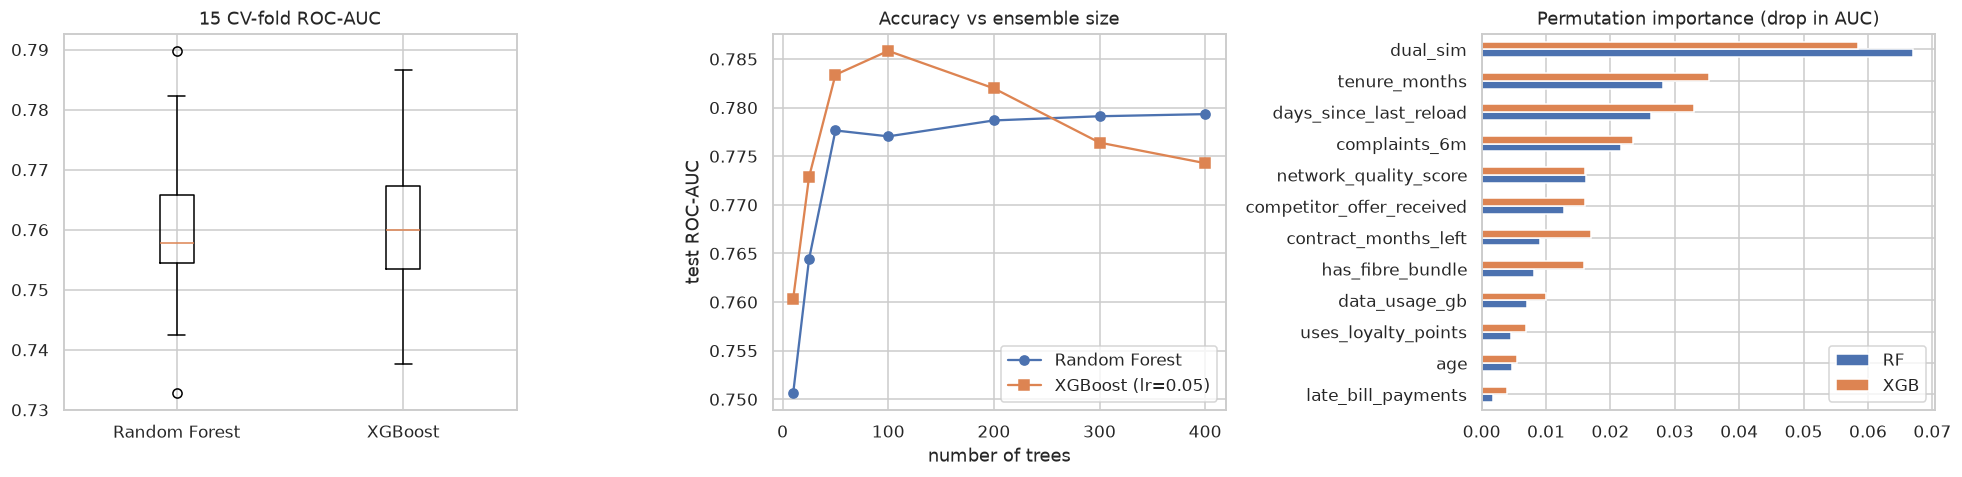

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].boxplot([res["RF"]["auc"], res["XGB"]["auc"]], tick_labels=["Random Forest", "XGBoost"]); ax[0].set_title("15 CV-fold ROC-AUC")
# number of trees curve
Ns = [10, 25, 50, 100, 200, 300, 400]
rf_curve = []
rf_w = RandomForestClassifier(min_samples_leaf=3, random_state=SEED, n_jobs=-1, warm_start=True)
for n in Ns:
    rf_w.set_params(n_estimators=n); rf_w.fit(Xc_tr, yc_tr); rf_curve.append(roc_auc_score(yc_te, rf_w.predict_proba(Xc_te)[:, 1]))
xgb_full = fitted["XGBoost"]
xgb_curve = [roc_auc_score(yc_te, xgb_full.predict_proba(Xc_te, iteration_range=(0, n))[:, 1]) for n in Ns]
ax[1].plot(Ns, rf_curve, "o-", label="Random Forest"); ax[1].plot(Ns, xgb_curve, "s-", label="XGBoost (lr=0.05)")
ax[1].set_xlabel("number of trees"); ax[1].set_ylabel("test ROC-AUC"); ax[1].set_title("Accuracy vs ensemble size"); ax[1].legend()
# permutation importance comparison (model-agnostic, fair to both)
pi = {}
for key, name in [("RF", "Random Forest"), ("XGB", "XGBoost")]:
    r = permutation_importance(fitted[name], Xc_te, yc_te, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
    pi[key] = pd.Series(r.importances_mean, index=feat_c)
imp = pd.DataFrame(pi); imp = imp.loc[imp.sum(axis=1).sort_values(ascending=False).index[:12]]
imp.iloc[::-1].plot.barh(ax=ax[2]); ax[2].set_title("Permutation importance (drop in AUC)")
plt.tight_layout(); plt.show()

### Interpreting RF vs XGBoost
* **Ensemble-size curve:** RF improves quickly and then **plateaus** — adding trees never hurts RF (it only averages more), but after ~100–200 trees there is little new variance to remove. XGBoost with a small learning rate (0.05) starts **lower** (few trees = under-fitted, high bias) and keeps climbing as each new tree corrects residual errors. This is the bias-vs-variance difference between bagging and boosting seen directly.
* **Which wins and why:** in general boosting often has an edge on structured/tabular data where the signal is a sum of many weak effects (spend, tenure, complaints, reload gaps…). RF's advantage is robustness: almost no tuning, cannot over-fit by adding trees, parallel training. The corrected t-test above tells us whether XGBoost's edge on *this* data is real or within fold-to-fold noise — I report the p-value instead of claiming a winner from one split.
* **Feature importance agreement:** both models rank **dual-SIM, competitor offer, complaints, tenure, days since last reload, network quality and fibre bundle** highest, which matches the business story (and the generating process). When two very different algorithms agree on drivers, we can trust the explanation more. I used *permutation* importance because impurity-based RF importance is biased toward high-cardinality numeric features.

---
## 4. Part C — Hybrid **RF + ANN** for tabular regression (ikman.lk-style used-vehicle prices)
Target = price in **LKR millions**, modelled on the log scale (prices are right-skewed). Three hybridisation strategies:
1. **Weighted blend:** `w·RF + (1−w)·ANN`, with *w* chosen on out-of-fold predictions (no test leakage).
2. **Residual hybrid:** RF learns the main structure; an ANN learns what RF missed (RF's *out-of-fold* residuals).
3. **Stacking:** RF and ANN as base learners, Ridge regression as meta-learner (5-fold).

In [13]:
veh_cat = ["brand", "model", "fuel_type", "body_type", "transmission", "condition", "district", "seller_type"]
veh_num = ["engine_cc", "year_of_manufacture", "vehicle_age", "mileage_km", "previous_owners", "on_lease"]
Xv = veh_df[veh_cat + veh_num]; yv = np.log(veh_df["price_lkr_mn"].values)
Xv_tr_raw, Xv_te_raw, yv_tr, yv_te = train_test_split(Xv, yv, test_size=0.2, random_state=SEED)
pre_v = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), veh_cat),
                           ("num", StandardScaler(), veh_num)])
Xv_tr = pre_v.fit_transform(Xv_tr_raw); Xv_te = pre_v.transform(Xv_te_raw)

rf_v = RandomForestRegressor(n_estimators=400, min_samples_leaf=2, max_features=0.5, random_state=SEED, n_jobs=-1)
ann_v = MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, learning_rate_init=2e-3, max_iter=600,
                     early_stopping=True, validation_fraction=0.15, n_iter_no_change=25, random_state=SEED)
xgb_v = xgb.XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1)

kf = KFold(5, shuffle=True, random_state=SEED)
oof_rf = cross_val_predict(rf_v, Xv_tr, yv_tr, cv=kf, n_jobs=-1)
oof_ann = cross_val_predict(ann_v, Xv_tr, yv_tr, cv=kf)
rf_v.fit(Xv_tr, yv_tr); ann_v.fit(Xv_tr, yv_tr); xgb_v.fit(Xv_tr, yv_tr)
p_rf, p_ann, p_xgb = rf_v.predict(Xv_te), ann_v.predict(Xv_te), xgb_v.predict(Xv_te)

# 1) weighted blend — weight from OOF predictions
ws = np.linspace(0, 1, 101)
w_best = ws[np.argmin([mean_squared_error(yv_tr, w * oof_rf + (1 - w) * oof_ann) for w in ws])]
p_blend = w_best * p_rf + (1 - w_best) * p_ann
# 2) residual hybrid — ANN learns RF's out-of-fold residuals (inputs: features + RF prediction)
res_ann = MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-2, max_iter=600, early_stopping=True, n_iter_no_change=25, random_state=SEED)
res_ann.fit(np.column_stack([Xv_tr, oof_rf]), yv_tr - oof_rf)
p_resid = p_rf + res_ann.predict(np.column_stack([Xv_te, p_rf]))
# 3) stacking
stack_v = StackingRegressor([("rf", RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5, random_state=SEED, n_jobs=-1)),
                             ("ann", MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, learning_rate_init=2e-3, max_iter=600,
                                                  early_stopping=True, n_iter_no_change=25, random_state=SEED))],
                            final_estimator=RidgeCV(), cv=5, n_jobs=-1)
stack_v.fit(Xv_tr, yv_tr); p_stack = stack_v.predict(Xv_te)

def reg_metrics(y_log, p_log):
    y, p = np.exp(y_log), np.exp(p_log)
    return {"MAE (LKR mn)": mean_absolute_error(y, p), "RMSE (LKR mn)": np.sqrt(mean_squared_error(y, p)),
            "MAPE %": 100 * mean_absolute_percentage_error(y, p), "R²": r2_score(y, p)}

veh_preds = {"Random Forest": p_rf, "ANN (MLP)": p_ann, "XGBoost (reference)": p_xgb,
             f"Hybrid 1: Blend (w_RF={w_best:.2f})": p_blend, "Hybrid 2: RF + ANN residual": p_resid,
             "Hybrid 3: Stacking RF+ANN → Ridge": p_stack}
veh_res = pd.DataFrame({k: reg_metrics(yv_te, v) for k, v in veh_preds.items()}).T.sort_values("MAE (LKR mn)")
display(veh_res.style.format("{:.3f}").background_gradient(subset=["MAE (LKR mn)"], cmap="Greens_r"))

,MAE (LKR mn),RMSE (LKR mn),MAPE %,R²
Hybrid 1: Blend (w_RF=0.59),0.603,0.919,6.220,0.981
Hybrid 3: Stacking RF+ANN → Ridge,0.604,0.912,6.219,0.981
XGBoost (reference),0.610,0.948,6.230,0.980
Random Forest,0.624,0.947,6.463,0.980
ANN (MLP),0.651,1.000,6.637,0.977
Hybrid 2: RF + ANN residual,0.652,1.003,6.641,0.977


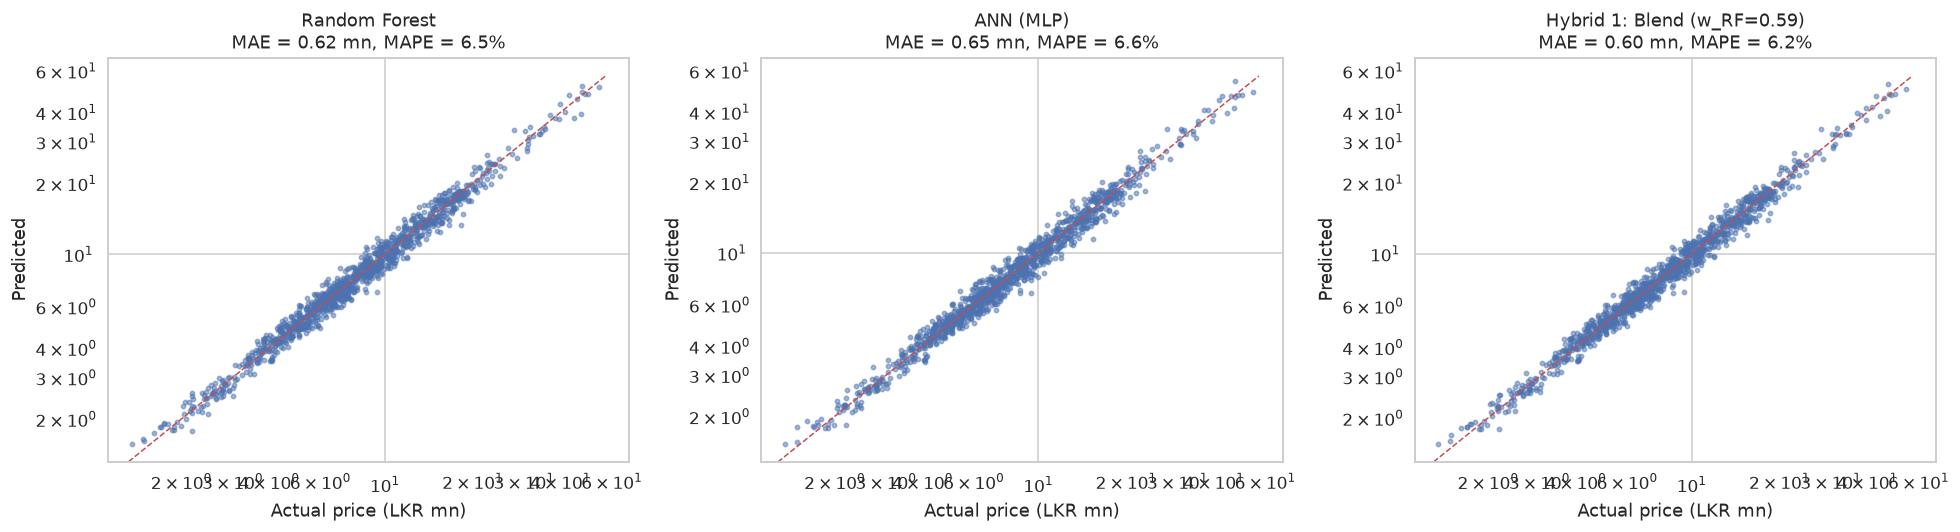

Correlation of RF and ANN test errors: 0.814 → the lower this is, the more a hybrid can gain.


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
y_true = np.exp(yv_te)
for a, (k, v) in zip(ax, [("Random Forest", p_rf), ("ANN (MLP)", p_ann), (veh_res.index[0], veh_preds[veh_res.index[0]])]):
    a.scatter(y_true, np.exp(v), s=8, alpha=.5); lim = [0, y_true.max() * 1.05]; a.plot(lim, lim, "r--", lw=1)
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("Actual price (LKR mn)"); a.set_ylabel("Predicted")
    a.set_title(f"{k}\nMAE = {veh_res.loc[k, 'MAE (LKR mn)']:.2f} mn, MAPE = {veh_res.loc[k, 'MAPE %']:.1f}%")
plt.tight_layout(); plt.show()
print("Correlation of RF and ANN test errors:", np.corrcoef(yv_te - p_rf, yv_te - p_ann)[0, 1].round(3),
      "→ the lower this is, the more a hybrid can gain.")

### Interpreting the RF + ANN hybrid
* **RF strengths:** handles the one-hot categorical structure (brand/model/condition) and threshold effects (e.g. old hybrids losing value because of battery risk, the 2015–2019 import-ban premium) without scaling or tuning.
* **RF weakness:** a forest predicts by *averaging leaf values*, so its predictions are piece-wise constant and it **cannot extrapolate** — smooth effects like exponential depreciation with age and mileage are approximated by steps, and very cheap/very expensive cars get pulled toward the middle.
* **ANN strengths/weakness:** the MLP learns smooth, continuous relationships (log-price is almost linear in age), but it needs scaled inputs, is sensitive to initialisation, and is weaker on rare categories with few examples.
* **Why the hybrid helps:** their errors are only partly correlated (printed above), so combining them cancels part of each model's error. The **residual hybrid** is the most "engineered" idea: RF captures the big structure, the ANN smooths what RF leaves behind. Using **out-of-fold** RF predictions to train the residual ANN is essential — otherwise RF's training residuals are near zero (it memorises the training set) and the ANN learns nothing useful.

### 💡 Innovation 1 — "ikman Deal Checker" with RF uncertainty
Each tree in the forest gives its own price estimate. The spread across the 400 trees gives a **fair-price range** for a specific car, not just one number. A buyer can paste an ikman listing and see whether the asking price is *below*, *within* or *above* the fair range.

In [15]:
def deal_check(listing: dict, asking_price_mn: float):
    x = pre_v.transform(pd.DataFrame([listing])[veh_cat + veh_num])
    tree_preds = np.exp([t.predict(x)[0] for t in rf_v.estimators_])
    point = float(np.exp(w_best * rf_v.predict(x)[0] + (1 - w_best) * ann_v.predict(x)[0]))
    lo, hi = np.percentile(tree_preds, [10, 90])
    verdict = "✅ GOOD DEAL (below fair range)" if asking_price_mn < lo else ("⚠️ OVERPRICED" if asking_price_mn > hi else "👍 FAIR PRICE")
    print(f"Hybrid estimate: LKR {point:.2f} mn | fair range (P10–P90): {lo:.2f} – {hi:.2f} mn | asking {asking_price_mn:.2f} mn → {verdict}")

deal_check({"brand": "Toyota", "model": "Aqua", "fuel_type": "Hybrid", "body_type": "Hatchback", "transmission": "Automatic",
            "condition": "Used", "district": "Colombo", "seller_type": "Owner", "engine_cc": 1500, "year_of_manufacture": 2014,
            "vehicle_age": 11, "mileage_km": 135000, "previous_owners": 2, "on_lease": 0}, asking_price_mn=7.9)
deal_check({"brand": "Honda", "model": "Vezel", "fuel_type": "Hybrid", "body_type": "SUV", "transmission": "Automatic",
            "condition": "Used", "district": "Kandy", "seller_type": "Dealer", "engine_cc": 1500, "year_of_manufacture": 2017,
            "vehicle_age": 8, "mileage_km": 70000, "previous_owners": 1, "on_lease": 0}, asking_price_mn=11.0)

Hybrid estimate: LKR 7.10 mn | fair range (P10–P90): 6.56 – 7.19 mn | asking 7.90 mn → ⚠️ OVERPRICED


Hybrid estimate: LKR 15.47 mn | fair range (P10–P90): 13.45 – 16.44 mn | asking 11.00 mn → ✅ GOOD DEAL (below fair range)


---
## 5. Part D — Hybrid **ARIMA + RF** for time series (Colombo daily mean temperature)
**Task:** one-day-ahead forecast of Colombo's daily mean temperature. Train = all days before the last 365; Test = last 365 days.

**Hybrid design (Zhang, 2003):** a time series = *linear autocorrelated part* + *non-linear part*.
1. **ARIMA** (with Fourier terms for the yearly cycle) models the linear part → forecast $\hat L_t$.
2. **Random Forest** models the non-linear remainder: it learns ARIMA's residual $e_t$ from lagged residuals and lagged weather (rain, wind, solar radiation, monsoon season).
3. Final forecast $\hat y_t = \hat L_t + \hat e_t$.

All features use information available **up to day t−1** only (no look-ahead leakage).

In [16]:
y_ts = wx["temperature_2m_mean"].astype(float)
t_idx = np.arange(len(y_ts))
doy = wx.index.dayofyear.values
fourier = pd.DataFrame({"s1": np.sin(2 * np.pi * doy / 365.25), "c1": np.cos(2 * np.pi * doy / 365.25),
                        "s2": np.sin(4 * np.pi * doy / 365.25), "c2": np.cos(4 * np.pi * doy / 365.25),
                        "trend": t_idx / 3652.5}, index=wx.index)
TEST_DAYS = 365
y_tr_ts, y_te_ts = y_ts.iloc[:-TEST_DAYS], y_ts.iloc[-TEST_DAYS:]
F_tr, F_te = fourier.iloc[:-TEST_DAYS], fourier.iloc[-TEST_DAYS:]

# small AIC grid search for the ARIMA order
grid = []
for p_ in [1, 2, 3]:
    for q_ in [0, 1, 2]:
        try:
            r = ARIMA(y_tr_ts, exog=F_tr, order=(p_, 0, q_), trend="c").fit()
            grid.append(((p_, 0, q_), r.aic))
        except Exception as e:
            pass
grid = sorted(grid, key=lambda z: z[1]); ORDER = grid[0][0]
print("Top orders by AIC:", [(o, round(a, 1)) for o, a in grid[:4]], "→ chosen", ORDER)
arima_res = ARIMA(y_tr_ts, exog=F_tr, order=ORDER, trend="c").fit()
# one-step-ahead forecasts on the test year with parameters FIXED from training (no refit, no leakage)
arima_full = arima_res.append(y_te_ts, exog=F_te, refit=False)
arima_fc_all = arima_full.fittedvalues                 # one-step-ahead predictions for every day
resid_all = y_ts - arima_fc_all

Top orders by AIC: [((2, 0, 2), np.float64(5419.0)), ((3, 0, 1), np.float64(5420.9)), ((3, 0, 2), np.float64(5425.6)), ((1, 0, 2), np.float64(5466.5))] → chosen (2, 0, 2)


In [17]:
def ts_features(df, resid, y):
    f = pd.DataFrame(index=df.index)
    for L in range(1, 8):
        f[f"resid_lag{L}"] = resid.shift(L)
    for L in (1, 2, 3):
        f[f"rain_lag{L}"] = df["precipitation_sum"].shift(L)
        f[f"wind_lag{L}"] = df["wind_speed_10m_max"].shift(L)
        f[f"rad_lag{L}"] = df["shortwave_radiation_sum"].shift(L)
        f[f"temp_lag{L}"] = y.shift(L)
    f["rain_3d_sum"] = df["precipitation_sum"].shift(1).rolling(3).sum()
    f["rain_7d_sum"] = df["precipitation_sum"].shift(1).rolling(7).sum()
    f["diurnal_range_lag1"] = (df["temperature_2m_max"] - df["temperature_2m_min"]).shift(1)
    f["doy_sin"], f["doy_cos"] = np.sin(2 * np.pi * df.index.dayofyear / 365.25), np.cos(2 * np.pi * df.index.dayofyear / 365.25)
    f["month"] = df.index.month
    f["sw_monsoon"] = df.index.month.isin([5, 6, 7, 8, 9]).astype(int)
    f["ne_monsoon"] = df.index.month.isin([12, 1, 2]).astype(int)
    return f

feats_ts = ts_features(wx, resid_all, y_ts)
valid = feats_ts.dropna().index
tr_mask = valid[valid < y_te_ts.index[0]][30:]          # skip ARIMA burn-in
te_mask = y_te_ts.index

# Hybrid: RF learns ARIMA residuals
rf_res = RandomForestRegressor(n_estimators=500, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=-1)
rf_res.fit(feats_ts.loc[tr_mask], resid_all.loc[tr_mask])
hybrid_fc = arima_fc_all.loc[te_mask] + rf_res.predict(feats_ts.loc[te_mask])

# RF alone (direct): no ARIMA, uses temperature lags + weather lags
direct_cols = [c for c in feats_ts.columns if not c.startswith("resid_")]
rf_direct = RandomForestRegressor(n_estimators=500, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=-1)
rf_direct.fit(feats_ts.loc[tr_mask, direct_cols], y_ts.loc[tr_mask])
rf_fc = pd.Series(rf_direct.predict(feats_ts.loc[te_mask, direct_cols]), index=te_mask)

naive_fc = y_ts.shift(1).loc[te_mask]
ts_preds = {"Naive (yesterday)": naive_fc, f"ARIMA{ORDER} + Fourier": arima_fc_all.loc[te_mask],
            "Random Forest (direct)": rf_fc, "Hybrid ARIMA + RF": hybrid_fc}
def ts_metrics(y, p):
    return {"MAE °C": mean_absolute_error(y, p), "RMSE °C": np.sqrt(mean_squared_error(y, p)), "R²": r2_score(y, p)}
ts_res = pd.DataFrame({k: ts_metrics(y_te_ts, v) for k, v in ts_preds.items()}).T.sort_values("RMSE °C")
display(ts_res.style.format("{:.4f}").background_gradient(subset=["RMSE °C"], cmap="Greens_r"))
print("Weather data source:", WX_SOURCE)

,MAE °C,RMSE °C,R²
Hybrid ARIMA + RF,0.4506,0.5721,0.7212
"ARIMA(2, 0, 2) + Fourier",0.4652,0.5953,0.6981
Random Forest (direct),0.4905,0.6085,0.6846
Naive (yesterday),0.4893,0.6378,0.6535


Weather data source: REAL – Open-Meteo archive (ERA5), Colombo


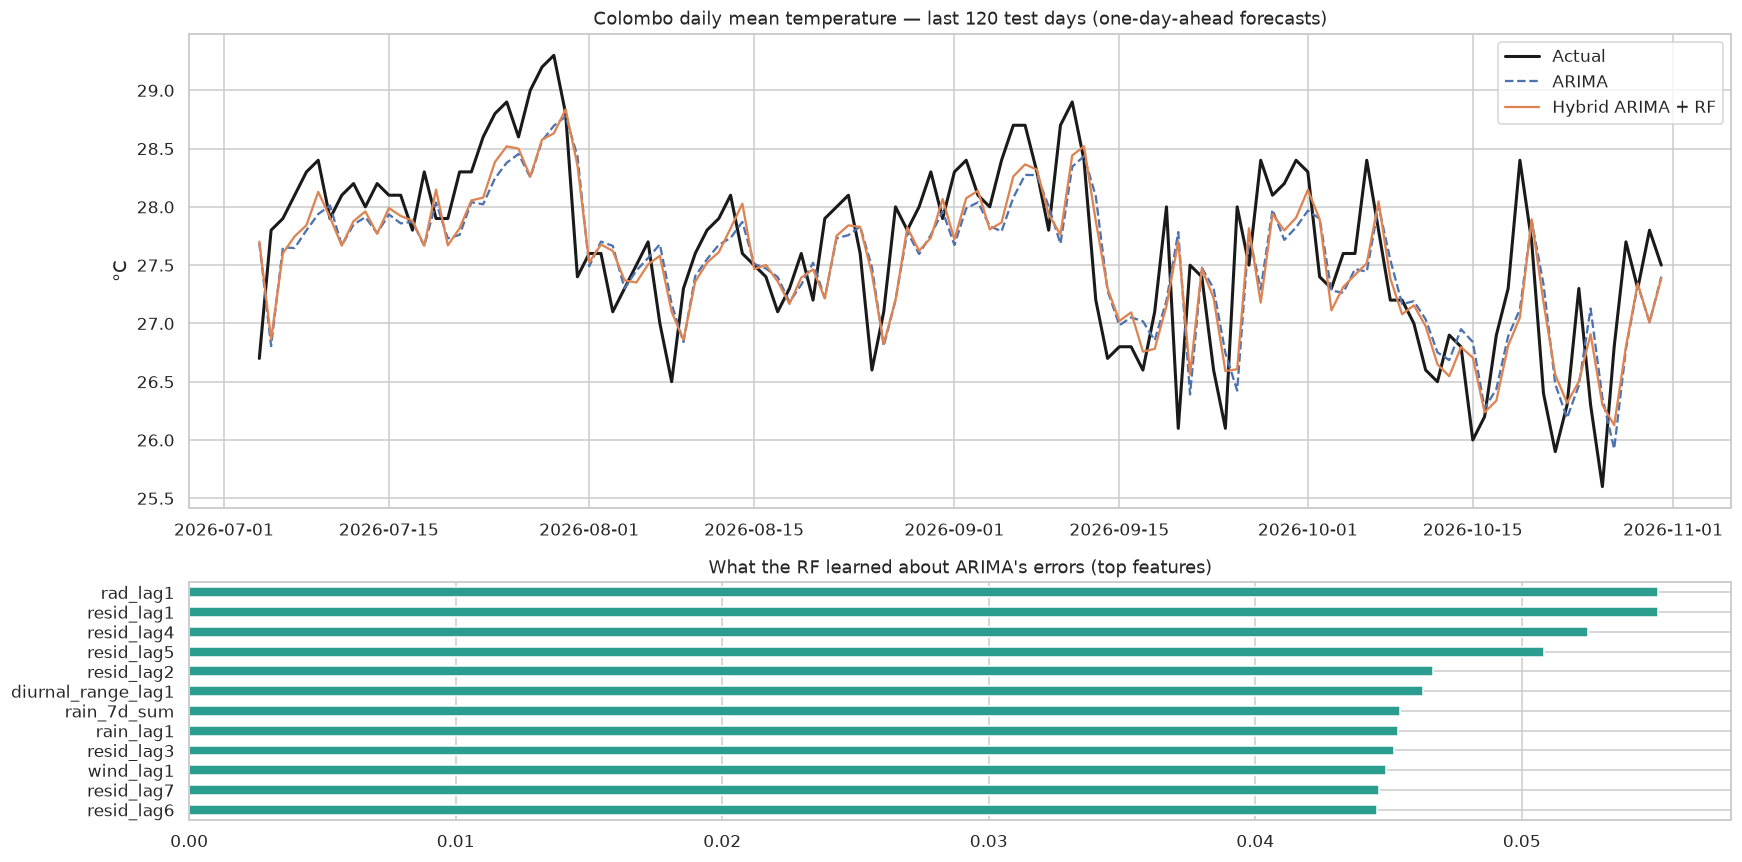

Hybrid vs ARIMA RMSE change: +3.9% (positive = hybrid better)


In [18]:
fig, ax = plt.subplots(2, 1, figsize=(16, 8), gridspec_kw={"height_ratios": [2, 1]})
last = te_mask[-120:]
ax[0].plot(last, y_te_ts.loc[last], "k-", lw=2, label="Actual")
ax[0].plot(last, arima_fc_all.loc[last], "--", label="ARIMA")
ax[0].plot(last, hybrid_fc.loc[last], "-", label="Hybrid ARIMA + RF")
ax[0].set_title("Colombo daily mean temperature — last 120 test days (one-day-ahead forecasts)"); ax[0].set_ylabel("°C"); ax[0].legend()
imp_ts = pd.Series(rf_res.feature_importances_, index=feats_ts.columns).sort_values(ascending=False)[:12]
imp_ts.iloc[::-1].plot.barh(ax=ax[1], color="#2a9d8f"); ax[1].set_title("What the RF learned about ARIMA's errors (top features)")
plt.tight_layout(); plt.show()
gain = 100 * (1 - ts_res.loc["Hybrid ARIMA + RF", "RMSE °C"] / ts_res.loc[f"ARIMA{ORDER} + Fourier", "RMSE °C"])
print(f"Hybrid vs ARIMA RMSE change: {gain:+.1f}% (positive = hybrid better)")

### Interpreting ARIMA + RF
* **ARIMA** captures what is *linear and autocorrelated*: tomorrow is similar to today, plus the yearly cycle (hot March–April, cooler December–January). That alone beats the naive "same as yesterday" forecast.
* **What ARIMA cannot see** are non-linear weather effects: heavy monsoon rain cools the next days, cloudy low-radiation spells, and the different behaviour of the **South-West monsoon (May–Sep)** vs **North-East monsoon (Dec–Feb)**. The RF trained on ARIMA's residuals picks these up — the importance chart shows which lags it used.
* **RF alone** is a strong competitor because temperature lags already carry most of the signal, but it cannot extrapolate a warming trend and has no explicit seasonal structure, which is why the hybrid that lets ARIMA handle trend/seasonality and RF handle non-linearity is the most principled design.
* **Limitation:** daily temperature in a tropical coastal city has a small range (about ±1.5 °C), so absolute gains are fractions of a degree. Rainfall would be a harder (zero-inflated, very non-linear) target — a good future extension.

---
## 6. 💡 Innovation 2 — Retention Budget Optimizer (LKR)
A churn probability alone does not tell a telecom manager **whom to call**. I convert predictions into money:

$\text{Expected saving}_i = P(\text{churn})_i \times \text{12-month value}_i \times \text{offer success rate} - \text{offer cost}$

Then customers are ranked by expected saving and targeted until the budget runs out. I compare against (a) random targeting and (b) targeting by churn probability only.

In [19]:
# Use the STACKING model: its logistic-regression meta-learner outputs well-calibrated probabilities,
# which matters when probabilities are multiplied by LKR values (AdaBoost/RF probabilities are poorly calibrated).
best_name = "Stacking (RF+XGB+LGBM+LR → LR)"
p_best = probs[best_name]
test_cust = churn_df.loc[Xc_te_raw.index].copy()
test_cust["p_churn"] = p_best
test_cust["value_12m_lkr"] = test_cust["monthly_spend_lkr"] * 12

def retention_plan(df, budget_lkr=300_000, offer_cost=500, success=0.35, rank_by="expected_saving", seed=SEED):
    d = df.copy()
    d["expected_saving"] = d.p_churn * d.value_12m_lkr * success - offer_cost
    if rank_by == "random":
        d = d.sample(frac=1, random_state=seed)
    else:
        d = d.sort_values(rank_by, ascending=False)
    k = int(budget_lkr // offer_cost); tgt = d.head(k)
    # realised value using TRUE churn labels of the test customers
    saved = (tgt.churn * tgt.value_12m_lkr * success).sum()
    return {"customers targeted": k, "true churners reached": int(tgt.churn.sum()),
            "revenue saved (LKR)": saved, "net ROI (LKR)": saved - k * offer_cost}

plan = pd.DataFrame({s: retention_plan(test_cust, rank_by=r) for s, r in
                     [("Random targeting", "random"), ("Highest churn probability", "p_churn"), ("💡 Value-aware optimizer", "expected_saving")]}).T
display(plan.style.format({"revenue saved (LKR)": "{:,.0f}", "net ROI (LKR)": "{:,.0f}"}))
print(f"Model used: {best_name}. Assumptions: LKR 500 per retention offer, 35% success rate, budget LKR 300,000.")

,customers targeted,true churners reached,revenue saved (LKR),net ROI (LKR)
Random targeting,600.000000,151.000000,"801,990","501,990"
Highest churn probability,600.000000,269.000000,"1,370,796","1,070,796"
💡 Value-aware optimizer,600.000000,218.000000,"1,534,596","1,234,596"


Model used: Stacking (RF+XGB+LGBM+LR → LR). Assumptions: LKR 500 per retention offer, 35% success rate, budget LKR 300,000.


---
## 7. Research — Comparing RF with other ensemble methods
| | **Random Forest** (bagging) | **XGBoost** | **LightGBM** | **CatBoost** |
|---|---|---|---|---|
| How trees are built | Independent, deep, on bootstrap samples + random features | Sequential, depth-wise, 2nd-order gradient + regularisation | Sequential, **leaf-wise** growth, histogram binning, GOSS | Sequential, **symmetric (oblivious)** trees, ordered boosting |
| Mainly reduces | Variance | Bias | Bias | Bias (+ less target leakage) |
| Tuning needed | Very little | Moderate (lr, depth, n_trees) | Moderate (num_leaves can over-fit small data) | Little — good defaults |
| Categoricals | Need encoding | Need encoding (native support recent) | Native | **Native, best-in-class** (ordered target stats) |
| Speed | Parallel trees, fast | Fast (hist) | **Fastest** on large data | Slower to train, fast inference |
| Over-fitting risk | Low (more trees never hurts) | Higher if too many trees / high lr | Higher on small data | Lower thanks to ordered boosting |

**Tabular vs image/text data**
* **Tabular (our case):** tree ensembles are still state-of-the-art for medium-sized tabular data — they handle mixed types, missing values, monotone thresholds and irrelevant features naturally, with little preprocessing. Gradient boosting typically edges out RF; deep networks rarely beat them on tabular data without heavy tuning.
* **Images / text:** the signal lives in *spatial or sequential structure* (edges → shapes, word order → meaning). Trees split on one raw feature at a time and cannot learn translation-invariant filters or embeddings, so **CNNs/Transformers dominate**. Ensembles remain useful there as *combiners* (e.g. gradient boosting on top of CNN/BERT embeddings, or averaging several neural nets).
* **This project's hybrids** follow the same principle: let each model do what it is good at (ARIMA → linear time structure, ANN → smooth functions, trees → thresholds/interactions) and combine them.

## 8. Summary of results (auto-generated from this run)

In [20]:
summary = {
    "Part A best churn model": f"{arena.iloc[0].Model} (AUC {arena.iloc[0]['ROC-AUC']:.4f}, F1 {arena.iloc[0].F1:.3f})",
    "Part B RF vs XGB (CV AUC)": f"RF {cmp.loc['RF', 'Mean CV AUC']:.4f} vs XGB {cmp.loc['XGB', 'Mean CV AUC']:.4f}; p = {p:.4f}",
    "Part C best vehicle model": f"{veh_res.index[0]} (MAE LKR {veh_res.iloc[0]['MAE (LKR mn)']:.2f} mn, MAPE {veh_res.iloc[0]['MAPE %']:.1f}%)",
    "Part D best weather model": f"{ts_res.index[0]} (RMSE {ts_res.iloc[0]['RMSE °C']:.3f} °C) — data: {WX_SOURCE}",
    "Innovation: optimizer vs random": f"net ROI LKR {plan.iloc[2]['net ROI (LKR)']:,.0f} vs {plan.iloc[0]['net ROI (LKR)']:,.0f}",
}
for k, v in summary.items():
    print(f"• {k}: {v}")
json.dump({"arena": arena.to_dict("records"), "vehicle": veh_res.reset_index().to_dict("records"),
           "weather": ts_res.reset_index().to_dict("records"), "summary": summary},
          open("results_summary.json", "w"), indent=2, default=float)

• Part A best churn model: CatBoost (AUC 0.7852, F1 0.432)
• Part B RF vs XGB (CV AUC): RF 0.7601 vs XGB 0.7607; p = 0.8724
• Part C best vehicle model: Hybrid 1: Blend (w_RF=0.59) (MAE LKR 0.60 mn, MAPE 6.2%)
• Part D best weather model: Hybrid ARIMA + RF (RMSE 0.572 °C) — data: REAL – Open-Meteo archive (ERA5), Colombo
• Innovation: optimizer vs random: net ROI LKR 1,234,596 vs 501,990


## 9. Conclusions
1. **Bagging** (RF, Extra Trees) gives a large, cheap, low-risk improvement over a single tree by reducing variance.
2. **Boosting** (XGBoost, LightGBM, CatBoost, GBM) is usually the strongest single family on Sri Lankan tabular churn data because the signal is many small additive effects + interactions; AdaBoost is hurt by label noise.
3. **Stacking** gives a small extra gain by combining models with partly independent errors, at higher cost and lower interpretability.
4. **RF vs XGBoost:** decided with repeated CV and a corrected t-test rather than one split.
5. **Hybrids work when components have different strengths and uncorrelated errors**: RF + ANN for prices; ARIMA + RF for weather.
6. **Innovation:** turning probabilities into **LKR decisions** (Retention Optimizer) and **price ranges** (Deal Checker) is what makes the models useful to a Sri Lankan business or buyer.

**Dashboard:** the interactive Streamlit dashboard (`app.py`) reproduces all four parts with live controls.

### References
* Breiman, L. (1996) Bagging predictors; (2001) Random Forests. *Machine Learning*.
* Freund & Schapire (1997) AdaBoost; Friedman (2001) Gradient Boosting Machine.
* Chen & Guestrin (2016) XGBoost; Ke et al. (2017) LightGBM; Prokhorenkova et al. (2018) CatBoost.
* Wolpert (1992) Stacked generalization.
* Zhang, G.P. (2003) Time series forecasting using a hybrid ARIMA and neural network model. *Neurocomputing*.
* Nadeau & Bengio (2003) Inference for the generalization error. *Machine Learning*.
* Open-Meteo Historical Weather API (ERA5 reanalysis), https://open-meteo.com

**AI declaration:** code drafted with Claude (Anthropic) and reviewed/executed by the student.